# 🌌 Exploring Stellar Populations Through Gaia DR3 Astrometric and Photometric Data

**Project:** Build a Hertzsprung–Russell (HR) diagram from real Gaia DR3 observations.

The HR diagram plots a star's **intrinsic brightness** (absolute magnitude) against its **colour** (temperature). It is one of the most important diagrams in astronomy because stars do not fill it randomly. They fall into distinct groups that reflect different stages of stellar evolution.

## Workflow
| Step | Task |
|---|---|
| 1 | Retrieve 5,000–10,000 stars from the Gaia DR3 archive |
| 2 | Filter unreliable parallax measurements |
| 3 | Calculate absolute magnitudes |
| 4 | Calculate colour index (BP − RP) |
| 5 | Construct the HR diagram |
| 6 | Identify the main sequence, red giant branch and white dwarf region |
| 7 | Discuss the distribution of stellar populations |

## 0. Background: the three quantities we need

**Parallax → distance.** Nearby stars appear to shift against the background as Earth orbits the Sun. Gaia measures this angle, the parallax $\varpi$ (in milliarcseconds):

$$d\;[\mathrm{pc}] = \frac{1000}{\varpi\;[\mathrm{mas}]}$$

**Distance → absolute magnitude.** Apparent magnitude $G$ depends on distance. Absolute magnitude $M_G$ is the brightness the star would have at 10 pc:

$$M_G = G - 5\log_{10}\!\left(\frac{d}{10\,\mathrm{pc}}\right) = G + 5\log_{10}\varpi\,[\mathrm{mas}] - 10$$

**Colour.** $BP - RP$ is the difference between Gaia's blue and red photometer magnitudes. **Small or negative = blue/hot, large = red/cool.** The Sun is about 0.82.

## 1. Setup

In [2]:
# Uncomment if astroquery is missing (Kaggle usually needs it):
!pip install -q astroquery

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from astropy import units as u
from astropy.coordinates import Distance
from astroquery.gaia import Gaia

warnings.filterwarnings("ignore", category=UserWarning)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

N_RAW        = 30000   # rows requested from Gaia (we filter these down afterwards)
MIN_PLX_SNR  = 10      # keep stars with parallax / parallax_error > this
MAX_RUWE     = 1.4     # astrometric quality (RUWE < 1.4 = good single-star fit)
N_FINAL_MAX  = 10000   # cap on the final sample size
CACHE_FILE   = "gaia_dr3_sample.csv"
SEED         = 42


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## 1. Retrieve a sample of stars from Gaia DR3

We use **ADQL** (Astronomical Data Query Language, SQL-like) through `astroquery`.

Design choices:
* `random_index` is a column Gaia provides that is **randomly distributed over the sky and the data**. Filtering on it and ordering by it gives a random sample instead of just the first rows the server happens to find (which would all come from one patch of sky).
* We only apply a **loose** server-side cut (`parallax_over_error > 3`) so that in Step 2 we can see the effect of the stricter quality filters.
* Only the columns we need are requested, which keeps the download small.

In [3]:
QUERY = f"""
SELECT TOP {N_RAW}
    source_id, ra, dec,
    parallax, parallax_error, parallax_over_error,
    phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag, bp_rp,
    ruwe
FROM gaiadr3.gaia_source
WHERE random_index < 5000000
  AND parallax_over_error > 3
  AND phot_g_mean_mag  IS NOT NULL
  AND phot_bp_mean_mag IS NOT NULL
  AND phot_rp_mean_mag IS NOT NULL
  AND ruwe IS NOT NULL
ORDER BY random_index
"""

if os.path.exists(CACHE_FILE):
    print(f"Loading cached data from {CACHE_FILE}")
    raw = pd.read_csv(CACHE_FILE)
else:
    print("Querying the Gaia archive (this can take ~30-90 s)...")
    Gaia.ROW_LIMIT = -1                       # don't truncate async results
    job = Gaia.launch_job_async(QUERY)
    raw = job.get_results().to_pandas()
    raw.to_csv(CACHE_FILE, index=False)
    print(f"Saved to {CACHE_FILE}")

print(f"\nRaw rows retrieved: {len(raw):,}")
raw.head()

Querying the Gaia archive (this can take ~30-90 s)...
INFO: Query finished. [astroquery.utils.tap.core]
Saved to gaia_dr3_sample.csv

Raw rows retrieved: 30,000


,source_id,ra,dec,parallax,parallax_error,parallax_over_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe
0,4267180339403392768,286.716913,0.276195,1.084924,0.033431,32.452808,15.244129,15.942071,14.419943,1.522128,1.033783
1,4479785133232857088,279.075733,9.748366,0.330182,0.073009,4.522506,17.185175,17.703926,16.532522,1.171404,0.958377
2,6709252873623174016,276.691194,-46.105121,0.206682,0.040105,5.153528,15.840754,16.380306,15.151749,1.228558,1.024658
3,4040289380503766784,267.088297,-35.827567,3.955271,1.083648,3.649958,19.080853,19.257017,17.627481,1.629536,3.453120
4,4040949706019490560,265.229363,-36.358205,0.352725,0.029665,11.890468,14.802705,16.118845,13.680644,2.438201,1.032197


### Quick look at the raw data
Always inspect the data before using it: shape, missing values, ranges.

In [4]:
display(raw.describe().T[["count", "mean", "min", "50%", "max"]].round(3))
print("\nMissing values per column:")
print(raw.isna().sum())

,count,mean,min,50%,max
source_id,30000.0,4.061501e+18,3.235863e+15,4.284583e+18,6.917177e+18
ra,30000.0,2.118040e+02,3.400000e-02,2.414430e+02,3.599730e+02
dec,30000.0,-1.104200e+01,-8.953900e+01,-1.809400e+01,8.886900e+01
parallax,30000.0,9.810000e-01,4.900000e-02,6.380000e-01,2.291100e+01
parallax_error,30000.0,1.420000e-01,8.000000e-03,8.200000e-02,3.059000e+00
parallax_over_error,30000.0,1.476200e+01,3.000000e+00,6.135000e+00,1.424213e+03
phot_g_mean_mag,30000.0,1.714200e+01,5.672000e+00,1.729900e+01,2.097200e+01
phot_bp_mean_mag,30000.0,1.787200e+01,5.785000e+00,1.794500e+01,2.312000e+01
phot_rp_mean_mag,30000.0,1.629400e+01,5.405000e+00,1.650900e+01,2.074100e+01
bp_rp,30000.0,1.577000e+00,-5.730000e-01,1.460000e+00,6.711000e+00



Missing values per column:
source_id              0
ra                     0
dec                    0
parallax               0
parallax_error         0
parallax_over_error    0
phot_g_mean_mag        0
phot_bp_mean_mag       0
phot_rp_mean_mag       0
bp_rp                  0
ruwe                   0
dtype: int64


## 2. Filter unreliable parallax measurements

Distances come from $1/\varpi$, which is only trustworthy when the parallax is measured precisely. If the fractional error $\sigma_\varpi/\varpi$ is large:
* the distance is very uncertain,
* the inversion $1/\varpi$ is biased,
* a negative or near-zero parallax would give a nonsense distance.

Cuts applied:

| Cut | Why |
|---|---|
| `parallax > 0` | negative parallaxes are noise and have no physical distance |
| `parallax_over_error > 10` | better than 10% precision, so $1/\varpi$ is a safe distance estimator |
| `ruwe < 1.4` | removes sources with poor astrometric fits (often unresolved binaries or crowded fields) |
| valid `bp_rp` | we need colour for the HR diagram |

In [5]:
df = raw.copy()
steps = [("Raw sample", len(df))]

df = df[df["parallax"] > 0];                         steps.append(("parallax > 0", len(df)))
df = df[df["parallax_over_error"] > MIN_PLX_SNR];    steps.append((f"parallax_over_error > {MIN_PLX_SNR}", len(df)))
df = df[df["ruwe"] < MAX_RUWE];                      steps.append((f"RUWE < {MAX_RUWE}", len(df)))
df = df.dropna(subset=["bp_rp", "phot_g_mean_mag"]); steps.append(("valid colour & G", len(df)))

# Cap the sample at N_FINAL_MAX (random, reproducible)
if len(df) > N_FINAL_MAX:
    df = df.sample(N_FINAL_MAX, random_state=SEED)
    steps.append((f"random subsample to {N_FINAL_MAX:,}", len(df)))
df = df.reset_index(drop=True)

summary = pd.DataFrame(steps, columns=["Step", "Stars remaining"])
display(summary)

if len(df) < 5000:
    print("\n⚠️ Fewer than 5,000 stars survived. Increase N_RAW or lower MIN_PLX_SNR.")

,Step,Stars remaining
0,Raw sample,30000
1,parallax > 0,30000
2,parallax_over_error > 10,9439
3,RUWE < 1.4,8974
4,valid colour & G,8974


### Did the cut help? Raw vs filtered sky and parallax quality
A quick sanity check: the sample should be spread across the whole sky (because we used `random_index`), and the filtered sample should have far smaller parallax uncertainties.

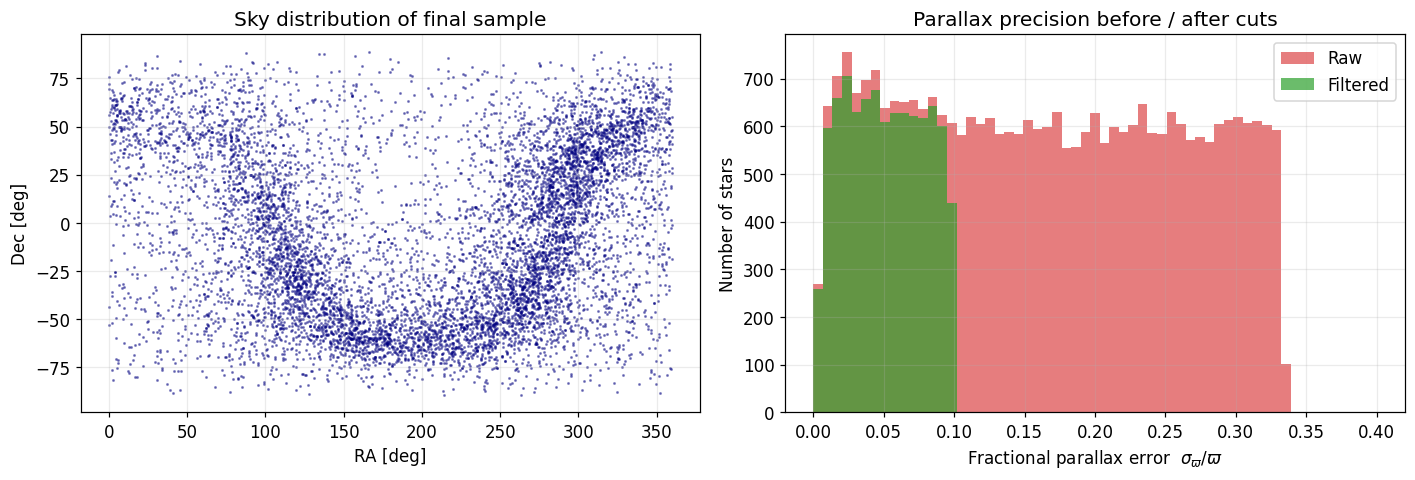

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].scatter(df["ra"], df["dec"], s=1, alpha=0.4, color="navy")
ax[0].set(xlabel="RA [deg]", ylabel="Dec [deg]", title="Sky distribution of final sample")

ax[1].hist(raw["parallax_error"] / raw["parallax"].clip(lower=1e-3), bins=np.linspace(0, 0.4, 60),
           alpha=0.6, label="Raw", color="tab:red")
ax[1].hist(df["parallax_error"] / df["parallax"], bins=np.linspace(0, 0.4, 60),
           alpha=0.7, label="Filtered", color="tab:green")
ax[1].set(xlabel=r"Fractional parallax error  $\sigma_\varpi / \varpi$", ylabel="Number of stars",
          title="Parallax precision before / after cuts")
ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Calculate distances and absolute magnitudes

We use **Astropy** to convert parallax into a distance and a *distance modulus* $\mu = 5\log_{10}(d/10\,\mathrm{pc})$, then

$$M_G = G - \mu$$

We also verify the result against the closed-form formula as a sanity check.

> 💡 **Note:** we ignore interstellar dust extinction and the small Gaia parallax zero-point offset (~ −0.017 mas). Both are second-order effects for this project and are discussed at the end.

In [8]:
# Parallax (mas) -> Distance object (Astropy handles the unit conversion)
dist = Distance(parallax=df["parallax"].values * u.mas)

df["distance_pc"] = dist.pc
df["M_G"] = df["phot_g_mean_mag"] - dist.distmod.value   # absolute G magnitude

# Sanity check against the textbook formula M = m + 5 log10(parallax_mas) - 10
M_check = df["phot_g_mean_mag"] + 5 * np.log10(df["parallax"]) - 10
assert np.allclose(df["M_G"], M_check), "Astropy and manual calculation disagree!"
print("Absolute magnitudes match the manual formula.\n")

display(df[["source_id", "phot_g_mean_mag", "parallax", "distance_pc", "bp_rp", "M_G"]].head())
print(f"\nDistance range: {df.distance_pc.min():.1f} - {df.distance_pc.max():.0f} pc "
      f"(median {df.distance_pc.median():.0f} pc)")

Absolute magnitudes match the manual formula.



,source_id,phot_g_mean_mag,parallax,distance_pc,bp_rp,M_G
0,4267180339403392768,15.244129,1.084924,921.723669,1.522128,5.421125
1,4040949706019490560,14.802705,0.352725,2835.070821,2.438201,2.539885
2,4517539583701880064,16.073896,0.674962,1481.563948,1.305249,5.220294
3,1823532754729083392,14.375696,0.886435,1128.114231,0.986587,4.113931
4,3586362911238437248,13.987773,7.191948,139.044379,1.819450,8.272006



Distance range: 47.8 - 8808 pc (median 1188 pc)


## 4. Colour index (BP − RP)

Gaia already provides `bp_rp`, but it is just the difference between the two photometric bands. Let's verify that and take a look at the distribution.

bp_rp matches BP - RP: True


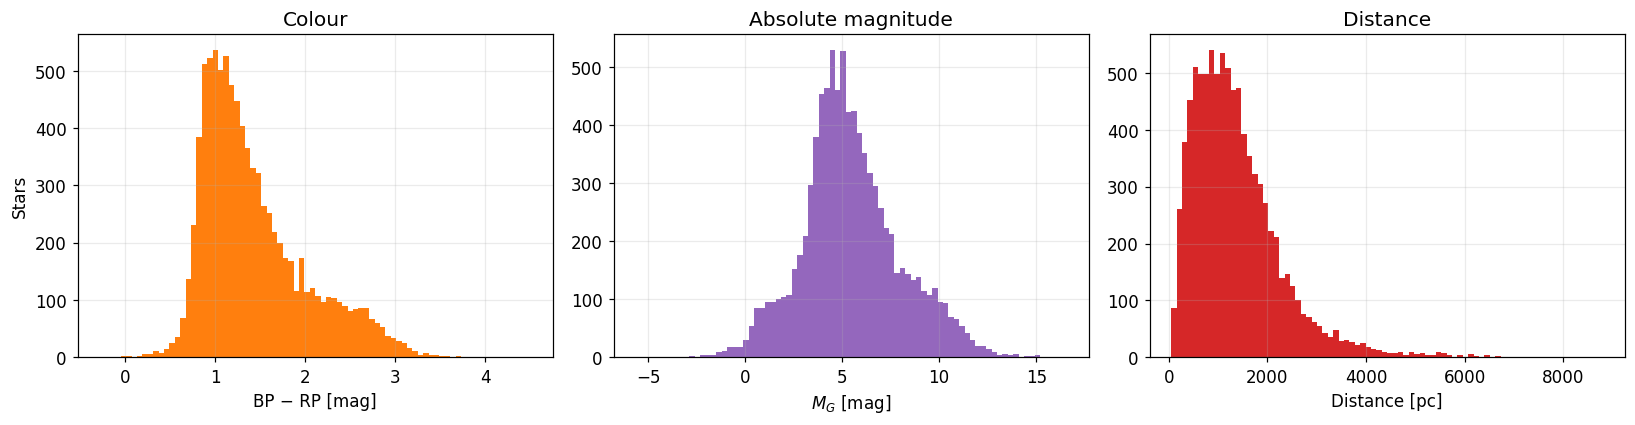

In [11]:
bp_rp_check = df["phot_bp_mean_mag"] - df["phot_rp_mean_mag"]
print("bp_rp matches BP - RP:", np.allclose(df["bp_rp"], bp_rp_check, atol=1e-3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["bp_rp"], bins=80, color="tab:orange");   ax[0].set(xlabel="BP − RP [mag]", ylabel="Stars", title="Colour")
ax[1].hist(df["M_G"], bins=80, color="tab:purple");     ax[1].set(xlabel=r"$M_G$ [mag]", title="Absolute magnitude")
ax[2].hist(df["distance_pc"], bins=80, color="tab:red"); ax[2].set(xlabel="Distance [pc]", title="Distance")
plt.tight_layout(); plt.show()

## 5. Construct the Hertzsprung–Russell diagram

Conventions:
* **x-axis:** colour BP − RP (blue/hot on the left, red/cool on the right)
* **y-axis:** absolute magnitude $M_G$, **inverted** so brighter stars are at the top (astronomers' convention: smaller magnitude = brighter)

We make two views: a **scatter plot** coloured by BP−RP, and a **density map**, which is better at revealing structure when points overlap.

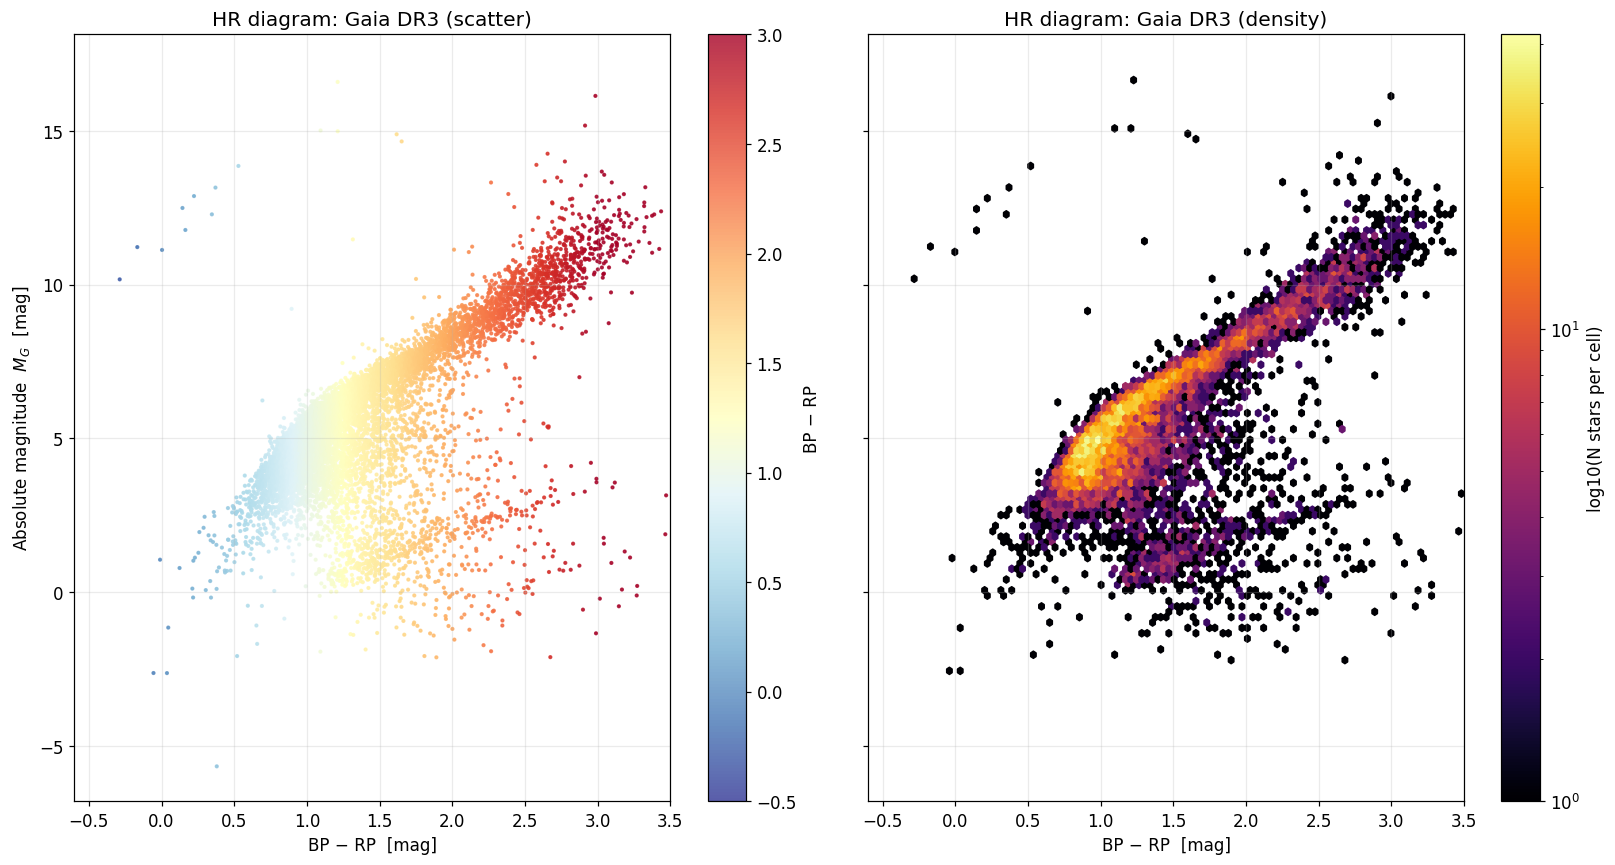

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)

# (a) scatter coloured by colour index
sc = axes[0].scatter(df["bp_rp"], df["M_G"], c=df["bp_rp"], s=3, cmap="RdYlBu_r",
                     vmin=-0.5, vmax=3.0, alpha=0.8)
axes[0].set(title="HR diagram: Gaia DR3 (scatter)", xlabel="BP − RP  [mag]", ylabel=r"Absolute magnitude  $M_G$  [mag]")
plt.colorbar(sc, ax=axes[0], label="BP − RP")

# (b) 2D density (log scale)
hb = axes[1].hexbin(df["bp_rp"], df["M_G"], gridsize=110, bins="log", cmap="inferno",
                    mincnt=1, extent=(-0.6, 3.5, -5, 17))
axes[1].set(title="HR diagram: Gaia DR3 (density)", xlabel="BP − RP  [mag]")
plt.colorbar(hb, ax=axes[1], label="log10(N stars per cell)")

for a in axes:
    a.invert_yaxis()
    a.set_xlim(-0.6, 3.5)
plt.tight_layout(); plt.show()

## 6. Identify the stellar populations

We define simple, transparent **rule-based regions** in the colour–magnitude plane. They are not meant to be perfect classifiers, just approximate boxes/lines that capture the three main features:

| Population | Where on the diagram | Physics |
|---|---|---|
| **White dwarfs** | Faint ($M_G \gtrsim 10$) and blue-ish, *below* the main sequence | Dense, cooling remnants of low-mass stars. Hot but tiny, so very low luminosity |
| **Red giant branch** | Bright and red, *above* the main sequence on the right | Evolved stars that have exhausted core hydrogen and swollen to large radii (cool but luminous) |
| **Main sequence** | The dense diagonal band from top-left to bottom-right | Stars fusing hydrogen in their cores, the longest phase of stellar life |

The white-dwarf boundary follows the approximate line used in the Gaia Collaboration HR-diagram paper (Babusiaux et al. 2018).

In [13]:
def classify_stars(color, mag):
    """Assign each star a population label from its (BP-RP, M_G) position.

    Rules are deliberately simple and approximate:
      * White dwarf  : well below the main sequence, blue-ish colours
      * Red giant    : bright (M_G < 3.5) and red (BP-RP > 0.95)
      * Main sequence: everything else (includes subgiants, which sit just above it)
    """
    color = np.asarray(color); mag = np.asarray(mag)
    labels = np.full(color.shape, "Main sequence", dtype=object)

    is_giant = (mag < 3.5) & (color > 0.95)
    is_wd    = (mag > 6.0) & (mag > 5.93 + 5.047 * color) & (color < 1.7)

    labels[is_giant] = "Red giant branch"
    labels[is_wd]    = "White dwarf"
    return labels

df["population"] = classify_stars(df["bp_rp"], df["M_G"])

counts = df["population"].value_counts()
table = pd.DataFrame({"N stars": counts, "Fraction [%]": (100 * counts / len(df)).round(2)})
display(table)

,N stars,Fraction [%]
population,,
Main sequence,7819,87.13
Red giant branch,1141,12.71
White dwarf,14,0.16


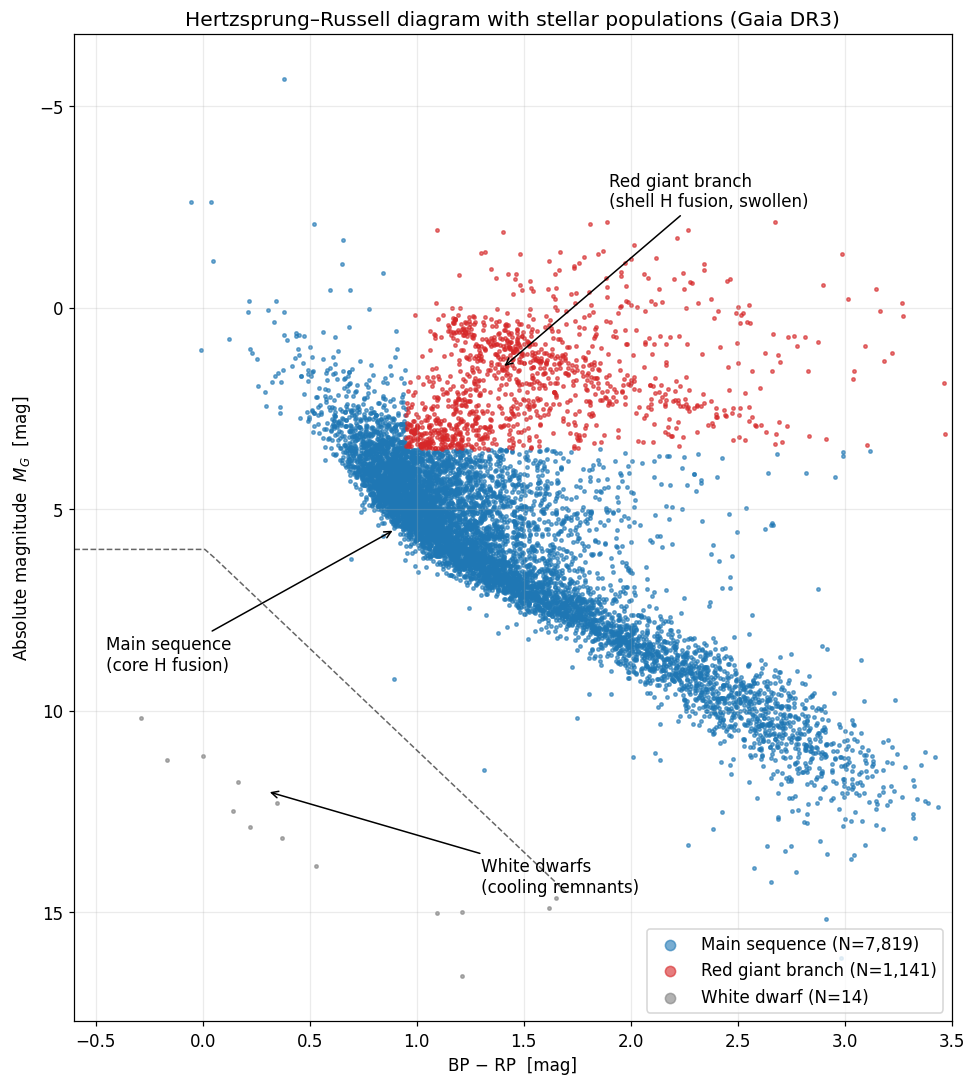

In [14]:
palette = {"Main sequence": "tab:blue", "Red giant branch": "tab:red", "White dwarf": "tab:gray"}

fig, ax = plt.subplots(figsize=(9, 10))
for name, colr in palette.items():
    sub = df[df["population"] == name]
    ax.scatter(sub["bp_rp"], sub["M_G"], s=5, alpha=0.6, color=colr, label=f"{name} (N={len(sub):,})")

# Draw the white-dwarf boundary line for reference
x = np.linspace(-0.6, 1.7, 50)
ax.plot(x, np.maximum(5.93 + 5.047 * x, 6.0), "k--", lw=1, alpha=0.6)

# Annotations
ax.annotate("Main sequence\n(core H fusion)", xy=(0.9, 5.5), xytext=(-0.45, 9),
            arrowprops=dict(arrowstyle="->"), fontsize=11)
ax.annotate("Red giant branch\n(shell H fusion, swollen)", xy=(1.4, 1.5), xytext=(1.9, -2.5),
            arrowprops=dict(arrowstyle="->"), fontsize=11)
ax.annotate("White dwarfs\n(cooling remnants)", xy=(0.3, 12), xytext=(1.3, 14.5),
            arrowprops=dict(arrowstyle="->"), fontsize=11)

ax.invert_yaxis()
ax.set(xlim=(-0.6, 3.5), xlabel="BP − RP  [mag]", ylabel=r"Absolute magnitude  $M_G$  [mag]",
       title="Hertzsprung–Russell diagram with stellar populations (Gaia DR3)")
ax.legend(loc="lower right", markerscale=3)
plt.tight_layout(); plt.show()

### Rough spectral-type colour bins
BP − RP maps (approximately) onto spectral type, since colour tracks surface temperature. These bins are rough and for illustration only.

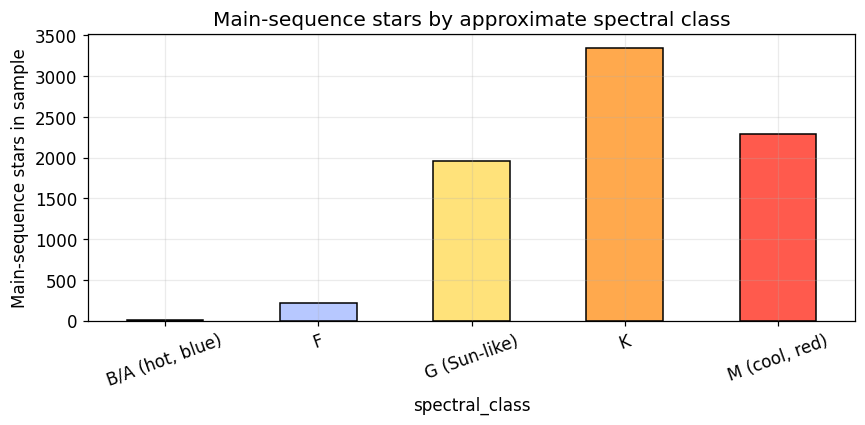

In [15]:
bins   = [-np.inf, 0.3, 0.7, 1.0, 1.6, np.inf]
labels = ["B/A (hot, blue)", "F", "G (Sun-like)", "K", "M (cool, red)"]
ms = df[df["population"] == "Main sequence"].copy()
ms["spectral_class"] = pd.cut(ms["bp_rp"], bins=bins, labels=labels)

spec = ms["spectral_class"].value_counts().reindex(labels)
ax = spec.plot(kind="bar", color=["#6a8dff", "#b7c8ff", "#ffe27a", "#ffa94d", "#ff5a4d"], figsize=(8, 4), edgecolor="k")
ax.set(ylabel="Main-sequence stars in sample", title="Main-sequence stars by approximate spectral class")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 7. Discussion: the distribution of stellar populations

Let's first print the numbers that will drive the discussion, then interpret them.

In [16]:
print("Median distance by population [pc]:")
print(df.groupby("population")["distance_pc"].median().round(0).to_string())

print("\nMedian M_G by population [mag]:")
print(df.groupby("population")["M_G"].median().round(2).to_string())

print("\nPopulation fractions [%]:")
print((100 * df["population"].value_counts(normalize=True)).round(2).to_string())

Median distance by population [pc]:
population
Main sequence       1087.0
Red giant branch    2577.0
White dwarf          117.0

Median M_G by population [mag]:
population
Main sequence        5.55
Red giant branch     1.92
White dwarf         13.02

Population fractions [%]:
population
Main sequence       87.13
Red giant branch    12.71
White dwarf          0.16


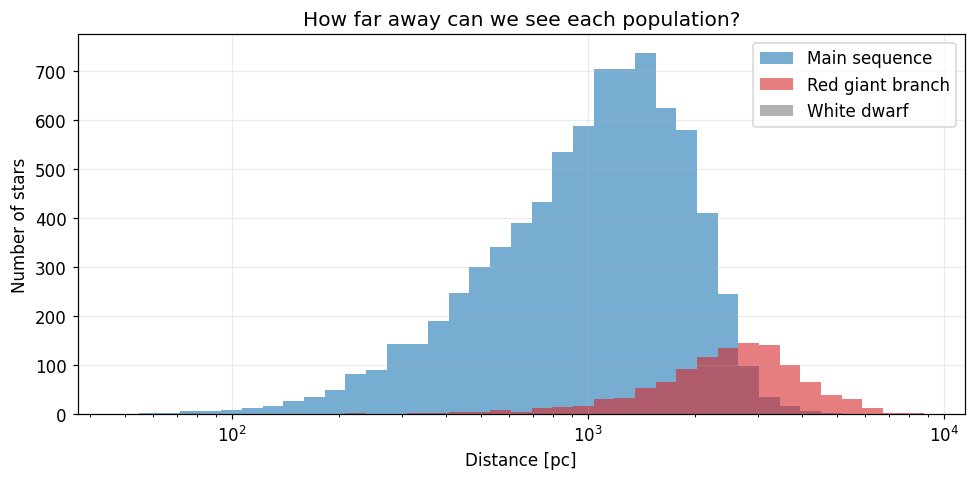

In [17]:
# Distance distribution per population. This is the key to understanding selection bias.
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, colr in palette.items():
    d = df.loc[df["population"] == name, "distance_pc"]
    ax.hist(d, bins=np.logspace(np.log10(df.distance_pc.min()), np.log10(df.distance_pc.max()), 40),
            alpha=0.6, color=colr, label=name)
ax.set(xscale="log", xlabel="Distance [pc]", ylabel="Number of stars", title="How far away can we see each population?")
ax.legend(); plt.tight_layout(); plt.show()

### Interpretation

**Main sequence.** The main sequence should dominate the sample, forming the tight diagonal band from hot, luminous stars (upper left) to cool, faint M dwarfs (lower right). It dominates because stars spend roughly 90% of their lives there, so this is where most stars are caught.

**Red giant branch (and red clump).** Giants are *intrinsically rare* but so luminous that Gaia can measure good parallaxes for them out to large distances. Look for a densely populated blob near $M_G \approx 0.5$, $BP-RP \approx 1.2$: the **red clump**, helium-burning giants that cluster in luminosity.

**White dwarfs.** White dwarfs are the endpoint of stars like our Sun. They are hot but only Earth-sized, so very faint ($M_G \gtrsim 10$). Because they are so faint, we can only get precise parallaxes for them if they are **very close**. In a parallax-quality-limited sample like this one, they are **heavily under-represented** compared with their true share of the Galaxy's stellar population.

### Selection effects: what this diagram does *not* tell you
1. **Parallax-limited ≠ volume-limited.** Luminous stars are visible to larger distances than faint ones, so giants and bright MS stars are over-represented, while faint M dwarfs and white dwarfs are under-represented (see the distance histogram above). The fractions in the table are properties of **our sample**, not of the Galaxy.
2. **Dust extinction.** Dust makes stars look redder and fainter. This smears the diagram and slightly displaces stars toward the lower right. Correcting it needs 3D dust maps.
3. **Unresolved binaries.** Two stars blended into one point source appear brighter, producing a visible "second main sequence" about 0.75 mag above the real one.
4. **Parallax zero-point and $1/\varpi$ bias.** Small residual systematics remain, especially for distant stars. A more careful analysis uses Bayesian distances (e.g. Bailer-Jones et al. 2021).
5. **Metallicity and age mix.** A single HR diagram blends young disk stars, old disk stars and halo stars. The broadening of the main sequence partly reflects this mix.

## 8. Bonus: volume-limited comparison (100 pc)

To demonstrate the selection effect directly, we query a **volume-limited** sample: every star with parallax > 10 mas (closer than 100 pc) and good astrometry. In this nearby volume Gaia can see even the faintest white dwarfs and M dwarfs.

INFO: Query finished. [astroquery.utils.tap.core]


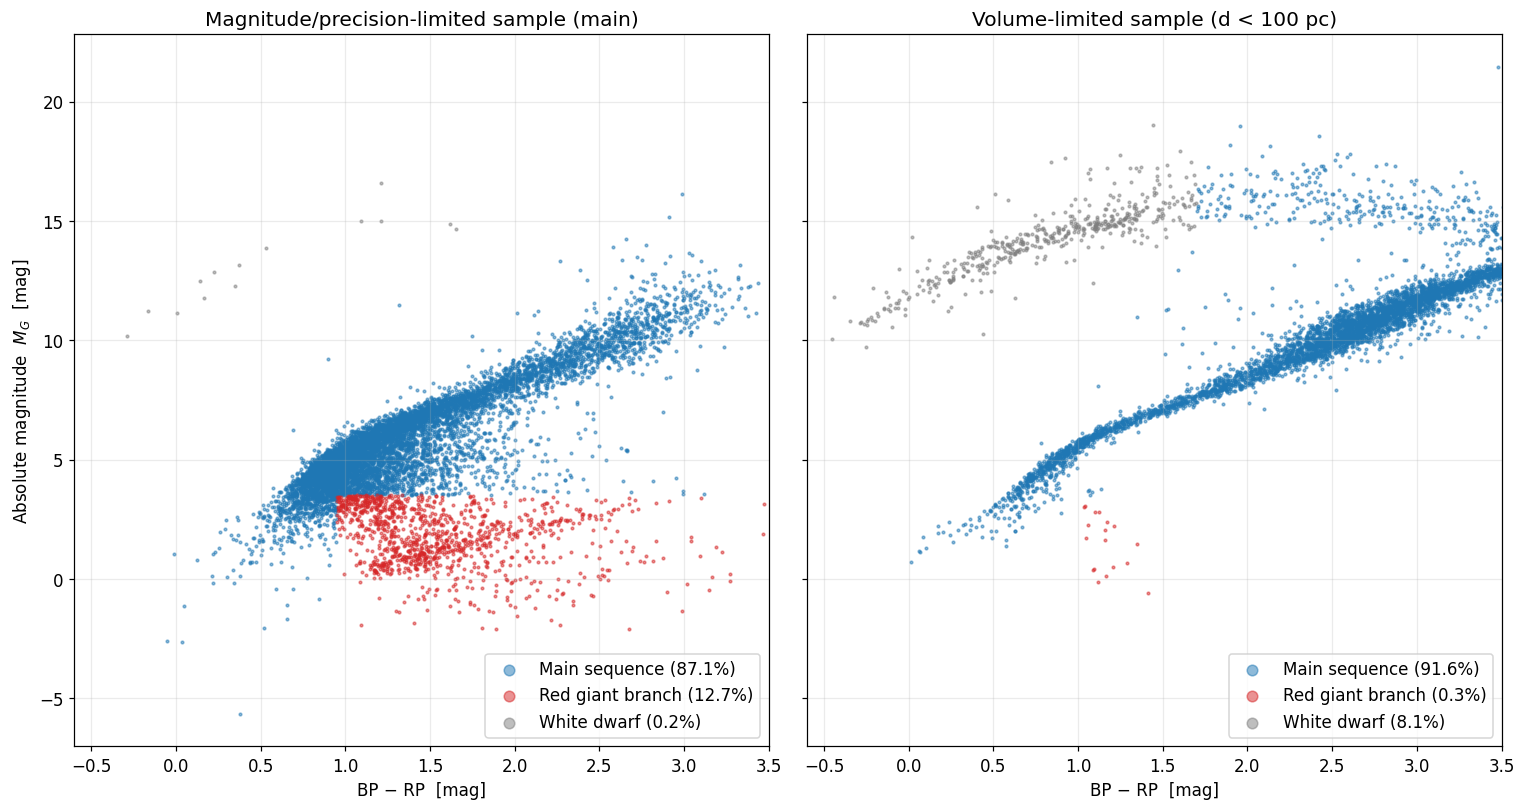

In [18]:
CACHE_100PC = "gaia_dr3_100pc.csv"
QUERY_100PC = """
SELECT TOP 10000
    source_id, parallax, parallax_over_error, phot_g_mean_mag, bp_rp, ruwe
FROM gaiadr3.gaia_source
WHERE random_index < 40000000
  AND parallax > 10
  AND parallax_over_error > 10
  AND ruwe < 1.4
  AND bp_rp IS NOT NULL
ORDER BY random_index
"""

if os.path.exists(CACHE_100PC):
    near = pd.read_csv(CACHE_100PC)
else:
    near = Gaia.launch_job_async(QUERY_100PC).get_results().to_pandas()
    near.to_csv(CACHE_100PC, index=False)

near["M_G"] = near["phot_g_mean_mag"] - Distance(parallax=near["parallax"].values * u.mas).distmod.value
near["population"] = classify_stars(near["bp_rp"], near["M_G"])

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
for a, data, title in zip(axes, [df, near], ["Magnitude/precision-limited sample (main)", "Volume-limited sample (d < 100 pc)"]):
    for name, colr in palette.items():
        s = data[data["population"] == name]
        a.scatter(s["bp_rp"], s["M_G"], s=3, alpha=0.5, color=colr, label=f"{name} ({100*len(s)/len(data):.1f}%)")
    a.invert_yaxis(); a.set_xlim(-0.6, 3.5)
    a.set(title=title, xlabel="BP − RP  [mag]")
    a.legend(markerscale=4, loc="lower right")
axes[0].set_ylabel(r"Absolute magnitude  $M_G$  [mag]")
plt.tight_layout(); plt.show()

## Conclusions
* Real Gaia DR3 data reproduces the classic structure of the HR diagram: a **main sequence**, a **red giant branch** (with a red clump), and a **white dwarf sequence**.
* Reliable absolute magnitudes require **careful parallax quality cuts**.
* Population fractions depend strongly on selection effects. A parallax-quality-limited sample favours luminous stars, whereas a volume-limited sample gives a fairer census of stellar types.

## References
* Gaia Collaboration, Vallenari et al. (2023), *Gaia Data Release 3: Summary of the content and survey properties*, A&A 674, A1
* Gaia Collaboration, Babusiaux et al. (2018), *Gaia DR2: Observational Hertzsprung–Russell diagrams*, A&A 616, A10
* Lindegren et al. (2021), *Gaia EDR3: Parallax bias versus magnitude, colour, and position*, A&A 649, A4
* Bailer-Jones et al. (2021), *Estimating distances from parallaxes. V.*, AJ 161, 147
* Astropy: https://www.astropy.org · Astroquery Gaia: https://astroquery.readthedocs.io/en/latest/gaia/gaia.html